=== 1. PODSUMOWANIE KORPUSU ===
Liczba zdań w pulach: budowla=20, mechanizm=20, neutralna=20
Łącznie zdań: 60 | Unikalnych słów po normalizacji: 320

Weryfikacja próbki BPE:
  zamek      (w korpusie: TAK) | zamkami      (w korpusie: NIE)
  mury       (w korpusie: TAK) | murowi       (w korpusie: NIE)
  klucz      (w korpusie: TAK) | kluczami     (w korpusie: NIE)
  drzwiach   (w korpusie: TAK) | drzwiami     (w korpusie: NIE)
  twierdzy   (w korpusie: TAK) | twierdzami   (w korpusie: NIE)
  ślusarz    (w korpusie: TAK) | ślusarzowi   (w korpusie: NIE)

=== 2. PORÓWNANIE TOKENIZACJI BPE ===
Limit    | Fakt. rozm. | Śr. tok. (widz.)  | [UNK] (widz.)  | Śr. tok. (niewidz.)  | [UNK] (niewidz.)
--------------------------------------------------------------------------------------------------
120      | 120         | 3.00              | 0              | 4.50                 | 0               
350      | 350         | 1.00              | 0              | 3.67                 | 0              

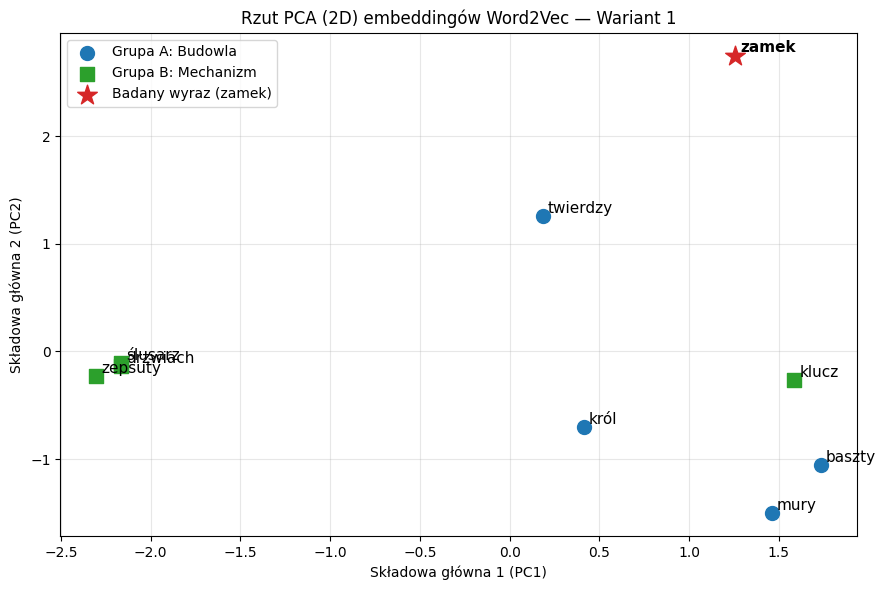

In [1]:

!pip -q install tokenizers gensim scikit-learn matplotlib numpy

import re
import numpy as np
import matplotlib.pyplot as plt
from tokenizers import Tokenizer, models, trainers, pre_tokenizers
from gensim.models import Word2Vec
from sklearn.decomposition import PCA

np.random.seed(0)


pula_budowla = [
    "Stary zamek stoi na wysokim wzgórzu nad rzeką.",
    "Turyści zwiedzają zamek oraz wysokie mury obronne.",
    "Król zamieszkał w warowni i rozbudował kamienny zamek.",
    "Potężne mury i baszty otaczają średniowieczny zamek.",
    "Rycerze bronili twierdzy zanim wróg zdobył zamek.",
    "Przewodnik opowiada o historii kiedy powstał ten zamek.",
    "Z wysokiej baszty widać cały zamek oraz okoliczne pola.",
    "Fosa z wodą skutecznie chroniła królewski zamek.",
    "Kamienny zamek przetrwał wielkie oblężenie wojsk.",
    "W podziemiach twierdzy ukryto skarby jakie miał zamek.",
    "Odbudowa ruin przywróciła dawny blask jaki nosił zamek.",
    "Dziedziniec otoczony krużgankami zdobi gotycki zamek.",
    "Turyści chętnie fotografują warowny zamek o zachodzie słońca.",
    "Mury obronne i głęboka fosa zabezpieczały każdy zamek.",
    "Król wydał wielką ucztę gdy odwiedził nowy zamek.",
    "Zbrojownia i kaplica znajdują się wewnątrz gdzie stoi zamek.",
    "Wysoka wieża strażnicza dominuje ponad całą budowlą jaką jest zamek.",
    "Średniowieczna twierdza oraz zamek przyciągają tłumy zwiedzających.",
    "Kamienne mury pamiętają czasy gdy król rządził przez zamek.",
    "Zwiedzanie komnat obejmuje również podziemia które skrywa zamek."
]


pula_mechanizm = [
    "Ślusarz naprawił zepsuty zamek w ciężkich drzwiach.",
    "Klucz nie pasuje ponieważ zaciął się zamek.",
    "Nowy zamek patentowy skutecznie zabezpiecza wejściowe drzwi.",
    "Złodziej próbował otworzyć zamek wytrychem w nocy.",
    "Wkładka i zapadka tworzą solidny metalowy zamek.",
    "Zgubiłem klucz więc muszę wymienić cały zamek.",
    "Stary zamek skrzypi przy każdym przekręceniu klucza.",
    "Solidne drzwi posiadają podwójny zamek antywłamaniowy.",
    "Mechanizm zapadkowy zablokował zamek od wewnętrznej strony.",
    "Ślusarz szybko otworzył zatrzaśnięty zamek bez uszkodzenia drzwi.",
    "Oliwa pomogła nasmarować zardzewiały zamek w furtce.",
    "Klamka opada ale zamek trzyma drzwi bardzo mocno.",
    "Kupiłem nowy klucz oraz zapasowy zamek do bramy.",
    "Wkładka bębenkowa stanowi najważniejszy element jaki ma zamek.",
    "Dziecko przypadkowo zatrzasnęło zamek w łazience.",
    "Monter zamontował elektroniczny zamek otwierany kodem.",
    "Zepsuty zamek uniemożliwił zamknięcie drzwi na klucz.",
    "Metalowa zasuwa wspomaga główny zamek w drzwiach wejściowych.",
    "Przekręciłem klucz dwa razy aby zamknąć zamek.",
    "Wymiana wkładki uratowała stary zamek przed złomowaniem."
]


pula_neutralna = [
    "Pogoda dzisiaj dopisuje i świeci jasne słońce.",
    "Pociąg osobowy odjeżdża z peronu drugiego punktualnie.",
    "Książka leży na drewnianym stole obok lampy.",
    "Student przygotowuje notatki przed trudnym egzaminem.",
    "Kawa o poranku dodaje energii do codziennej pracy.",
    "W lesie rosną wysokie sosny oraz stare dęby.",
    "Rzeka płynie spokojnie przez zieloną dolinę.",
    "Komputer przetwarza duże zbiory danych w chmurze.",
    "Samochód jedzie szeroką drogą w stronę miasta.",
    "Kucharz przygotowuje smaczny obiad ze świeżych warzyw.",
    "Muzyka klasyczna pomaga skupić się podczas nauki.",
    "Sklep spożywczy jest otwarty do późnego wieczora.",
    "Rowerzysta jedzie ścieżką wzdłuż miejskiego parku.",
    "Deszcz pada od rana i tworzy kałuże na chodniku.",
    "Kot śpi spokojnie na miękkim fotelu w salonie.",
    "Telefon dzwoni głośno w cichym pokoju.",
    "Ogrodnik podlewa kolorowe kwiaty w przydomowym ogrodzie.",
    "Malarz tworzy piękny obraz na dużym płótnie.",
    "Lekarz bada pacjenta w nowoczesnym gabinecie.",
    "Nauczyciel tłumaczy trudne zagadnienie przy tablicy."
]

def normalizuj(zdanie):
    return re.sub(r'[^\w\s]', '', zdanie.lower()).strip()

korpus_pelny = [normalizuj(s) for s in (pula_budowla + pula_mechanizm + pula_neutralna)]
slownik_korpusu = set(" ".join(korpus_pelny).split())

print("=== 1. PODSUMOWANIE KORPUSU ===")
print(f"Liczba zdań w pulach: budowla={len(pula_budowla)}, mechanizm={len(pula_mechanizm)}, neutralna={len(pula_neutralna)}")
print(f"Łącznie zdań: {len(korpus_pelny)} | Unikalnych słów po normalizacji: {len(slownik_korpusu)}")


pary_bpe = [
    ("zamek", "zamkami"),
    ("mury", "murowi"),
    ("klucz", "kluczami"),
    ("drzwiach", "drzwiami"),
    ("twierdzy", "twierdzami"),
    ("ślusarz", "ślusarzowi")
]

print("\nWeryfikacja próbki BPE:")
for w, nw in pary_bpe:
    assert w in slownik_korpusu and nw not in slownik_korpusu
    print(f"  {w:<10} (w korpusie: TAK) | {nw:<12} (w korpusie: NIE)")



limity_vocab = [120, 350, 800]
formy_widziane = [p[0] for p in pary_bpe]
formy_niewidziane = [p[1] for p in pary_bpe]

tokenizery = {}
print("\n=== 2. PORÓWNANIE TOKENIZACJI BPE ===")
print(f"{'Limit':<8} | {'Fakt. rozm.':<11} | {'Śr. tok. (widz.)':<17} | {'[UNK] (widz.)':<14} | {'Śr. tok. (niewidz.)':<20} | {'[UNK] (niewidz.)':<16}")
print("-" * 98)

for limit in limity_vocab:
    tok = Tokenizer(models.BPE(unk_token='[UNK]'))
    tok.pre_tokenizer = pre_tokenizers.Whitespace()
    trainer = trainers.BpeTrainer(vocab_size=limit, special_tokens=['[UNK]'], min_frequency=1)
    tok.train_from_iterator(korpus_pelny, trainer)
    tokenizery[limit] = tok

    toks_w = [tok.encode(w).tokens for w in formy_widziane]
    sr_w = np.mean([len(t) for t in toks_w])
    unk_w = sum(1 for t in toks_w if '[UNK]' in t)

    toks_nw = [tok.encode(w).tokens for w in formy_niewidziane]
    sr_nw = np.mean([len(t) for t in toks_nw])
    unk_nw = sum(1 for t in toks_nw if '[UNK]' in t)

    print(f"{limit:<8} | {tok.get_vocab_size():<11} | {sr_w:<17.2f} | {unk_w:<14} | {sr_nw:<20.2f} | {unk_nw:<16}")

print("\nPodział dwóch niewidzianych form dla wszystkich limitów:")
for slowo in ["zamkami", "ślusarzowi"]:
    print(f"  Słowo '{slowo}':")
    for limit in limity_vocab:
        print(f"    vocab_size={limit:<3} (faktyczny={tokenizery[limit].get_vocab_size()}): {tokenizery[limit].encode(slowo).tokens}")



wariant_1_raw = pula_neutralna + pula_budowla[:12] + pula_mechanizm[:4]
wariant_2_raw = pula_neutralna + pula_budowla[:4] + pula_mechanizm[:12]

zdania_w1 = [normalizuj(s).split() for s in wariant_1_raw] * 10
zdania_w2 = [normalizuj(s).split() for s in wariant_2_raw] * 10

w2v_params = dict(vector_size=40, window=4, min_count=2, sg=1, epochs=150, seed=42, workers=1)
model_1 = Word2Vec(zdania_w1, **w2v_params)
model_2 = Word2Vec(zdania_w2, **w2v_params)

sasiedzi_1 = model_1.wv.most_similar('zamek', topn=5)
sasiedzi_2 = model_2.wv.most_similar('zamek', topn=5)

print("\n=== 3. TOP 5 SĄSIADÓW SŁOWA 'zamek' W WORD2VEC ===")
print(f"{'Poz.':<5} | {'Wariant 1 (12 budowla / 4 mech.)':<34} | {'Wariant 2 (4 budowla / 12 mech.)':<34}")
print("-" * 80)
for i in range(5):
    s1 = f"{sasiedzi_1[i][0]} ({sasiedzi_1[i][1]:.3f})"
    s2 = f"{sasiedzi_2[i][0]} ({sasiedzi_2[i][1]:.3f})"
    print(f"{i+1:<5} | {s1:<34} | {s2:<34}")

print("\nSprawdzenie słów, które wypadły z TOP 5 Wariantu 1 w Modelu 2:")
top5_w2_slowa = {w for w, _ in sasiedzi_2}
for w, _ in sasiedzi_1:
    if w not in top5_w2_slowa:
        if w in model_2.wv:
            print(f"  '{w}' -> nadal ma wektor w Modelu 2 (podobieństwo do 'zamek': {model_2.wv.similarity('zamek', w):.3f})")
        else:
            print(f"  '{w}' -> wypadło ze słownika Modelu 2 (poniżej min_count)")



grupa_budowla = ['mury', 'król', 'twierdzy', 'baszty']
grupa_mechanizm = ['klucz', 'drzwiach', 'ślusarz', 'zepsuty']
badany = 'zamek'

slowa_pca = grupa_budowla + grupa_mechanizm + [badany]
wektory = np.stack([model_1.wv[w] for w in slowa_pca])
xy = PCA(n_components=2, random_state=0).fit_transform(wektory)

def sr_cos_wewnatrz(grupa):
    pary = [(grupa[i], grupa[j], model_1.wv.similarity(grupa[i], grupa[j]))
            for i in range(len(grupa)) for j in range(i + 1, len(grupa))]
    return np.mean([p[2] for p in pary]), pary

def sr_cos_miedzy(g1, g2):
    pary = [(w1, w2, model_1.wv.similarity(w1, w2)) for w1 in g1 for w2 in g2]
    return np.mean([p[2] for p in pary]), pary

sr_A, pary_A = sr_cos_wewnatrz(grupa_budowla)
sr_B, pary_B = sr_cos_wewnatrz(grupa_mechanizm)
sr_AB, pary_AB = sr_cos_miedzy(grupa_budowla, grupa_mechanizm)

print("\n=== 4. ŚREDNIE PODOBIEŃSTWO COSINUSOWE (WEKTORY 40D, MODEL 1) ===")
print(f"Wewnątrz Grupy A (Budowla) [{len(pary_A)} par]:   {sr_A:.4f}")
print(f"Wewnątrz Grupy B (Mechanizm) [{len(pary_B)} par]: {sr_B:.4f}")
print(f"Między Grupą A a Grupą B [{len(pary_AB)} par]:    {sr_AB:.4f}")
print(f"Przykładowa para wewnątrz grupy ('mury' - 'baszty'):   {model_1.wv.similarity('mury', 'baszty'):.4f}")
print(f"Przykładowa para między grupami ('król' - 'ślusarz'):  {model_1.wv.similarity('król', 'ślusarz'):.4f}\n")

# Rysowanie wykresu PCA
plt.figure(figsize=(9, 6))
for i, w in enumerate(slowa_pca):
    if w in grupa_budowla:
        kolor, marker, etykieta = '#1f77b4', 'o', 'Grupa A: Budowla'
    elif w in grupa_mechanizm:
        kolor, marker, etykieta = '#2ca02c', 's', 'Grupa B: Mechanizm'
    else:
        kolor, marker, etykieta = '#d62728', '*', 'Badany wyraz (zamek)'

    plt.scatter(xy[i, 0], xy[i, 1], c=kolor, marker=marker, s=220 if w == badany else 100, label=etykieta, zorder=3)
    plt.annotate(w, (xy[i, 0] + 0.03, xy[i, 1] + 0.03), fontsize=11, fontweight='bold' if w == badany else 'normal')

handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys(), loc='best')
plt.title('Rzut PCA (2D) embeddingów Word2Vec — Wariant 1')
plt.xlabel('Składowa główna 1 (PC1)')
plt.ylabel('Składowa główna 2 (PC2)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()